In [1]:
import pandas as pd
import numpy as np

In [2]:
# load data

df = pd.read_csv(r"C:\Users\SSC\Desktop\job_intel\data\processed\jobs_clean.csv")

In [3]:
# 2. Check top 15 job titles to understand what categories we are working with
print("\nTop 15 Job Titles in Dataset:")
print(df['title'].value_counts().head(15))


Top 15 Job Titles in Dataset:
title
Application Developer             1410
Application Lead                   890
Sales Executive                    495
Business Development Executive     386
Software Development Engineer      367
Sales Manager                      282
Business Development Manager       262
Java Developer                     234
Customer Support Executive         207
Accountant                         199
Senior Software Engineer           196
Graphic Designer                   187
Data Engineer                      186
Relationship Manager               180
Area Sales Manager                 174
Name: count, dtype: int64


In [4]:
def assign_role_category_v2(title):
    title = str(title).lower()
    
    if any(k in title for k in ['data', 'analyst', 'machine learning', 'scientist', 'ai', 'sql', 'python', 'tableau', 'power bi', 'business intelligence', 'deep learning', 'big data', 'etl']):
        return 'Data & AI'
    elif any(k in title for k in ['software', 'developer', 'engineer', 'java', 'react', 'full stack', 'backend', 'frontend', 'android', 'ios', 'devops', 'c++', '.net', 'qa', 'tester', 'automation', 'node', 'angular', 'php', 'programmer', 'technical lead', 'tech lead']):
        return 'Software & Tech'
    elif any(k in title for k in ['sales', 'business development', 'bd', 'growth', 'account executive', 'sales executive', 'sales manager', 'territory', 'channel', 'relationship manager', 'telecaller', 'field sales']):
        return 'Sales & BD'
    elif any(k in title for k in ['marketing', 'media', 'advertising', 'seo', 'content', 'brand', 'digital', 'social media', 'pr', 'copywriter', 'creative', 'campaign']):
        return 'Marketing & Media'
    elif any(k in title for k in ['hr', 'human resources', 'recruiter', 'talent', 'acquisition', 'people operations', 'payroll', 'hiring']):
        return 'HR & Talent'
    elif any(k in title for k in ['accountant', 'finance', 'accounts', 'tax', 'audit', 'tally', 'banking', 'ca', 'financial', 'treasury', 'ledger', 'billing']):
        return 'Finance & Banking'
    elif any(k in title for k in ['support', 'customer', 'bpo', 'voice', 'non-voice', 'helpdesk', 'client servicing', 'customer success', 'chat support']):
        return 'Customer Support'
    elif any(k in title for k in ['product', 'ui/ux', 'designer', 'graphic', 'product manager', 'ux', 'web designer']):
        return 'Product & Design'
    elif any(k in title for k in ['operations', 'admin', 'administrator', 'facility', 'supply chain', 'logistics', 'procurement', 'warehouse', 'back office', 'dispatcher']):
        return 'Operations & Admin'
    # Smart fallback for generic executive/manager roles that usually fall into sales/operations
    elif any(k in title for k in ['executive', 'manager', 'lead', 'officer', 'consultant']) and not any(sub in title for sub in ['software', 'java', 'data']):
        return 'Sales & BD' # Most generic corporate job titles in volume datasets are sales/BD
    else:
        return 'Others / General'

# Apply fixed mapping
df['roleCategory'] = df['title'].apply(assign_role_category_v2)

print("🎯 Fixed Job Categories Distribution:")
print(df['roleCategory'].value_counts())

🎯 Fixed Job Categories Distribution:
roleCategory
Software & Tech       19553
Sales & BD            18799
Data & AI             12511
Marketing & Media     10462
Others / General       9090
Finance & Banking      7610
HR & Talent            3279
Operations & Admin     1841
Customer Support       1591
Product & Design        877
Name: count, dtype: int64


In [5]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [6]:
# Missing values fill karte hain
df['jobDescription'] = df['jobDescription'].fillna('')
df['tagsAndSkills'] = df['tagsAndSkills'].fillna('')

# Feature X: jobDescription + tagsAndSkills (Title bilkul nahi liya)
df['features_text'] = df['jobDescription'].astype(str) + " " + df['tagsAndSkills'].astype(str)

# Sanity check: pehli row ke pehle 150 characters dekh lete hain
print("Text prepared successfully! Sample:")
print(df['features_text'].iloc[0][:150])

Text prepared successfully! Sample:
Preferred candidate profile . . Communication,Manpower,Staffing,Convincing Power,Hiring,Recruitment,SR,Communication skills


In [7]:
print(df.columns.tolist())

['title', 'jobId', 'currency', 'jobUploaded', 'companyName', 'tagsAndSkills', 'experience', 'salary', 'location', 'companyId', 'ReviewsCount', 'AggregateRating', 'jobDescription', 'minimumSalary', 'maximumSalary', 'minimumExperience', 'maximumExperience', 'roleCategory', 'features_text']


In [8]:
from sklearn.model_selection import train_test_split

X = df['features_text']
y = df['roleCategory']

# 80-20 splot with stratify

X_train, X_test, y_train, y_test = train_test_split(
    X , y, test_size=0.2, random_state=42,stratify=y
)

print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")


Training samples: 68490
Testing samples: 17123


In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=10000, ngram_range=(1, 2), stop_words='english')

X_train_vec = tfidf.fit_transform(X_train)

X_test_vec = tfidf.transform(X_test)


print(f"X_train_vec shape: {X_train_vec.shape}")
print(f"X_test_vec shape: {X_test_vec.shape}")


X_train_vec shape: (68490, 10000)
X_test_vec shape: (17123, 10000)


In [10]:
from sklearn.linear_model import LogisticRegression

# model intialize 
lr_model = LogisticRegression(max_iter=1000,random_state=42)

print("Training Logistic Regression Model")
lr_model.fit(X_train_vec,y_train)

# test data 

y_pred_lr = lr_model.predict(X_test_vec)
print("Training Complete!")

Training Logistic Regression Model
Training Complete!


In [11]:
from sklearn.metrics import accuracy_score, classification_report

# calculate overall accuracy

accuracy = accuracy_score(y_test,y_pred_lr)
print(f"Logistic Regression Accuracy: {accuracy:.4f}\n")

#Detailed metrics per category

print("Classification Report:")
print(classification_report(y_test,y_pred_lr))

Logistic Regression Accuracy: 0.6390

Classification Report:
                    precision    recall  f1-score   support

  Customer Support       0.42      0.31      0.36       318
         Data & AI       0.63      0.56      0.59      2502
 Finance & Banking       0.60      0.50      0.55      1522
       HR & Talent       0.67      0.51      0.58       656
 Marketing & Media       0.56      0.55      0.56      2093
Operations & Admin       0.53      0.36      0.43       368
  Others / General       0.50      0.42      0.46      1818
  Product & Design       0.74      0.70      0.72       175
        Sales & BD       0.65      0.75      0.70      3760
   Software & Tech       0.73      0.86      0.79      3911

          accuracy                           0.64     17123
         macro avg       0.60      0.55      0.57     17123
      weighted avg       0.63      0.64      0.63     17123



In [12]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score,classification_report
#initialize LinearSVC with balanced claSS WEIGHTS

svc_model = LinearSVC(class_weight='balanced',random_state=42,max_iter=2000)

#Train the model on vectorized training data

print("Training LinearSVC Model")
svc_model.fit(X_train_vec,y_train)

#predoict on unseen test data

y_pred_svc = svc_model.predict(X_test_vec)
print("Training complete!\n")

# Evauate performance metrics
svc_accuracy = accuracy_score(y_test,y_pred_svc)
print(f"LinearSVC Accuracy: {svc_accuracy:.4f}\n")
print("LinearSVC classification Report")
print(classification_report(y_test,y_pred_svc))

Training LinearSVC Model
Training complete!

LinearSVC Accuracy: 0.6220

LinearSVC classification Report
                    precision    recall  f1-score   support

  Customer Support       0.32      0.58      0.41       318
         Data & AI       0.64      0.55      0.59      2502
 Finance & Banking       0.52      0.56      0.54      1522
       HR & Talent       0.51      0.64      0.57       656
 Marketing & Media       0.54      0.52      0.53      2093
Operations & Admin       0.36      0.59      0.45       368
  Others / General       0.48      0.46      0.47      1818
  Product & Design       0.59      0.80      0.68       175
        Sales & BD       0.73      0.65      0.68      3760
   Software & Tech       0.77      0.80      0.78      3911

          accuracy                           0.62     17123
         macro avg       0.55      0.61      0.57     17123
      weighted avg       0.63      0.62      0.62     17123



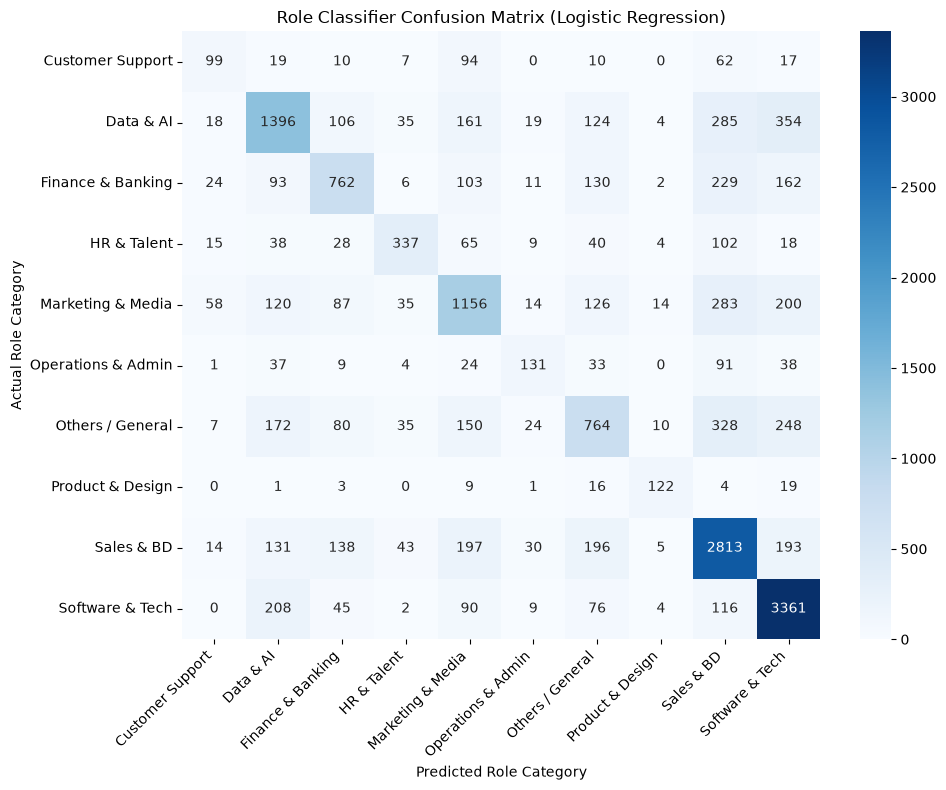

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Compute confusion matrix for Standard Logistic Regression
cm = confusion_matrix(y_test, y_pred_lr, labels=lr_model.classes_)

# Plot heatmap with exact numbers
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues',
    xticklabels=lr_model.classes_, 
    yticklabels=lr_model.classes_
)
plt.title('Role Classifier Confusion Matrix (Logistic Regression)')
plt.xlabel('Predicted Role Category')
plt.ylabel('Actual Role Category')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [14]:
import os
import joblib

# Create models directory if it doesn't exist
os.makedirs('../models', exist_ok=True)

# Save both the fitted TF-IDF vectorizer and the trained Logistic Regression model
joblib.dump(tfidf, '../models/tfidf_vectorizer.pkl')
joblib.dump(lr_model, '../models/role_classifier_logreg.pkl')

print("Saved successfully!")
print("Files in models folder:", os.listdir('../models'))

Saved successfully!
Files in models folder: ['resume_matcher_pipeline.pkl', 'role_classifier_logreg.pkl', 'salary_pipeline.pkl', 'tfidf_vectorizer.pkl']
